# Hands-On Module 3: Diamond Price Prediction
## Google Developer Group, Bandung Institute of Technology

**Dataset:** `sns.load_dataset('diamonds')`
**Tools:** NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn

Pipeline: EDA → preprocessing → train-test split → linear regression → evaluation → polynomial regression → model comparison, plus Bonus 1–3.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<8} MAE={mae:9.2f}  RMSE={rmse:9.2f}  R2={r2:.4f}")
    return mae, rmse, r2

---
## Stage 1: Data Preparation and EDA

### 1.1 Load, inspect, and clean dimensional anomalies

In [2]:
df = sns.load_dataset("diamonds")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df[["x", "y", "z"]].describe().T

Shape: (53940, 10)
Missing values: 0
Duplicate rows: 146


,count,mean,std,min,25%,50%,75%,max
x,53940.0,5.7312,1.1218,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.7345,1.1421,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.5387,0.7057,0.0,2.91,3.53,4.04,31.80


In [3]:
zero_dim = (df.x == 0) | (df.y == 0) | (df.z == 0)
print("Rows with a zero dimension:", zero_dim.sum())
print("Rows with y > 20 or z > 20:", ((df.y > 20) | (df.z > 20)).sum())
df[zero_dim | (df.y > 20) | (df.z > 20)][["carat", "x", "y", "z", "price"]]

Rows with a zero dimension: 20
Rows with y > 20 or z > 20: 3


,carat,x,y,z,price
2207,1.00,6.55,6.48,0.00,3142
2314,1.01,6.66,6.60,0.00,3167
4791,1.10,6.50,6.47,0.00,3696
5471,1.01,6.50,6.47,0.00,3837
10167,1.50,7.15,7.04,0.00,4731
11182,1.07,0.00,6.62,0.00,4954
11963,1.00,0.00,0.00,0.00,5139
13601,1.15,6.88,6.83,0.00,5564
15951,1.14,0.00,0.00,0.00,6381
24067,2.00,8.09,58.90,8.06,12210


**Observation:** There are no missing values. `x`, `y`, `z` contain two kinds of anomaly:

- **20 rows with a dimension of 0.** A diamond cannot have zero length, width, or depth, so these are missing values coded as 0.
- **3 rows with `y` or `z` of 31.8 to 58.9 mm** (e.g. a 0.51 carat stone with `z = 31.8`). A 0.51 carat diamond is about 5 mm across, so these are typos (probably a misplaced decimal point). The 2.00 carat stone with `y = 58.9` is the same kind of error: its `x` and `z` are about 8 mm.

**Decision: drop these rows instead of imputing.** Together they are 23 of 53,940 rows (0.04%), so dropping loses almost nothing. Imputing `x`/`y`/`z` would also be questionable because the three dimensions are strongly tied to `carat`, so an imputed value could look plausible but still be wrong. I filter with `x, y, z > 0` and `y, z < 20`, which is slightly stricter than the course snippet (it also removes zero `y`/`z`).

I keep the legitimately large stones (4 to 5 carat, `x` and `y` about 10 mm). They are rare but real, and they carry information about the top of the price range.

The 146 duplicate rows are kept: many diamonds share the same attributes, and nothing in the data says they are mistakes.

In [4]:
df_clean = df[(df.x > 0) & (df.y > 0) & (df.z > 0) & (df.y < 20) & (df.z < 20)].reset_index(drop=True)
print("Shape after cleaning:", df_clean.shape, f"({len(df) - len(df_clean)} rows removed)")
df_clean[["x", "y", "z"]].describe().T

Shape after cleaning: (53917, 10) (23 rows removed)


,count,mean,std,min,25%,50%,75%,max
x,53917.0,5.7316,1.1194,3.73,4.71,5.70,6.54,10.74
y,53917.0,5.7334,1.1113,3.68,4.72,5.71,6.54,10.54
z,53917.0,3.5394,0.6916,1.07,2.91,3.53,4.04,6.98


### 1.2 Correlation heatmap

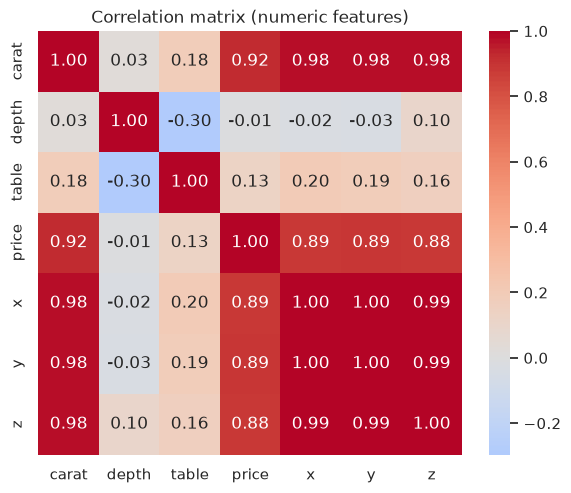

carat    0.9216
y        0.8888
x        0.8872
z        0.8821
table    0.1272
depth   -0.0107
Name: price, dtype: float64

In [5]:
corr = df_clean.corr(numeric_only=True)
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (numeric features)")
plt.show()

price_corr = corr["price"].drop("price").sort_values(ascending=False)
price_corr

**Highest correlation with `price`:** `carat` (0.92) and `y` (0.89); `x` (0.89) is practically tied with `y`.
**Lowest correlation with `price`:** `depth` (-0.01), which is essentially zero, and then `table` (0.13).

**Multicollinearity warning:** `carat`, `x`, `y`, `z` are all correlated with each other at about 0.95 to 0.99 (carat is a weight, and weight grows with the cube of size). Together they carry mostly the same information, which will matter when we read the regression coefficients in Stage 2.4.

### 1.3 Distribution of `price` and the log-transform

Skewness price     : 1.618
Skewness log(price): 0.115


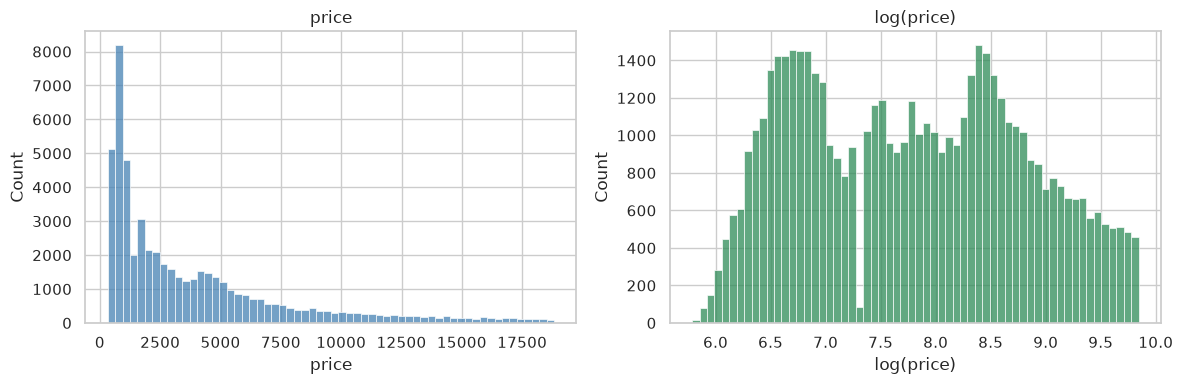

In [6]:
print(f"Skewness price     : {df_clean.price.skew():.3f}")
print(f"Skewness log(price): {np.log(df_clean.price).skew():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_clean.price, bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("price")
sns.histplot(np.log(df_clean.price), bins=60, ax=axes[1], color="seagreen")
axes[1].set_title("log(price)")
axes[1].set_xlabel("log(price)")
plt.tight_layout()
plt.show()

**Observation:** `price` is strongly right-skewed (skewness 1.62): most diamonds are cheap, and a long tail of expensive ones stretches to about $18,800. `log(price)` has skewness 0.12 and looks much closer to a bell shape (with a mild double hump).

**Recommendation:** A log-transform is worth trying for the target. Linear regression is fitted with squared error, so a long tail of expensive diamonds dominates the loss, and errors in dollars grow with the price. I keep the original scale for the main Stages 2 to 4 (the task asks for it, and RMSE stays in dollars), and test the transform properly in Bonus 1.

### 1.4 `carat` vs `price` by `cut`

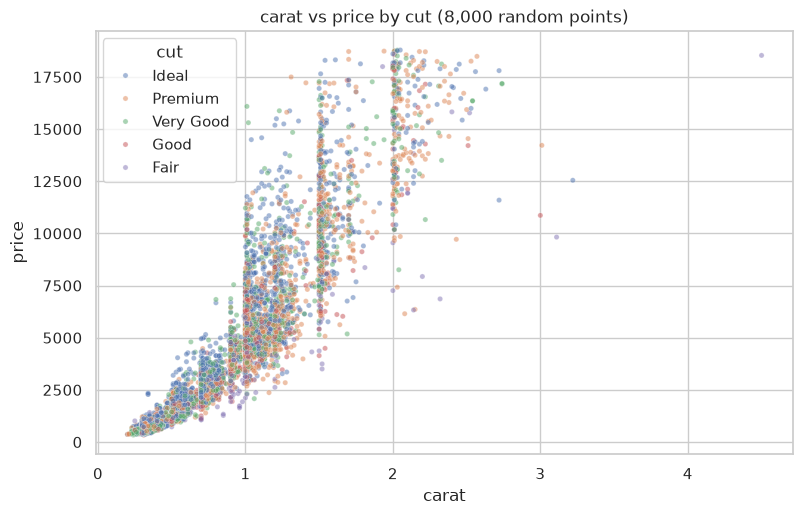

,mean_price,mean_carat
cut,,
Ideal,3457.0053,0.7028
Premium,4579.1308,0.8913
Very Good,3981.8306,0.8064
Good,3926.4035,0.8487
Fair,4357.5009,1.0461


In [7]:
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df_clean.sample(8000, random_state=42), x="carat", y="price",
                hue="cut", alpha=0.5, s=14,
                hue_order=["Ideal", "Premium", "Very Good", "Good", "Fair"])
plt.title("carat vs price by cut (8,000 random points)")
plt.show()

df_clean.groupby("cut", observed=True).agg(mean_price=("price", "mean"), mean_carat=("carat", "mean"))

**Is it linear?** No. Price rises faster than linearly with carat and the spread widens with size: for 1 carat stones 90% of prices fall between about $3,300 and $8,800, and for 2 carats between about $9,800 and $18,300. The relationship is curved, and the variance grows with the price (heteroscedasticity). We also see horizontal bands at "round" weights (0.5, 1.0, 1.5, 2.0 carat) because buyers prefer those sizes.

**Does cut influence it?** Only weakly and in a confusing way. At the same carat, the colours are heavily mixed, so cut alone does not separate the cloud into layers. The table even shows that *Fair* cut diamonds have a higher average price than *Ideal* ones, because Fair diamonds are on average larger (higher mean carat). Cut is confounded with carat, so we cannot read the price effect of cut from the raw averages. Its true effect has to be measured with carat held fixed, which we do in Bonus 2.

---
## Stage 2: Multiple Linear Regression

### 2.1 Train-test split (80/20, `random_state=42`)
The split happens **before** any scaler is fitted, so the test set cannot leak into training.

In [8]:
num_feats = ["carat", "depth", "table", "x", "y", "z"]
X = df_clean[num_feats]
y = df_clean["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (43133, 6)  Test: (10784, 6)


### 2.2 Pipeline: `StandardScaler` + `LinearRegression`

In [9]:
lin_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])
lin_pipe.fit(X_train, y_train)

pred_train = lin_pipe.predict(X_train)
pred_test = lin_pipe.predict(X_test)
res_lin = {}
res_lin["train"] = report("Train", y_train, pred_train)
res_lin["test"] = report("Test", y_test, pred_test)

Train    MAE=   890.25  RMSE=  1493.77  R2=0.8599
Test     MAE=   873.51  RMSE=  1453.64  R2=0.8659


**Interpretation:** The model explains about 86% of the variance in price (R² 0.860 train, 0.866 test). The train and test scores are almost identical, so there is **no overfitting**; the remaining error is a limit of the model (underfitting), not of the data size. On average a prediction is off by about $874 (MAE), and the RMSE of $1,454 is much larger than the MAE, which says that a minority of predictions are far off, mostly on expensive stones.

### 2.3 Residual analysis

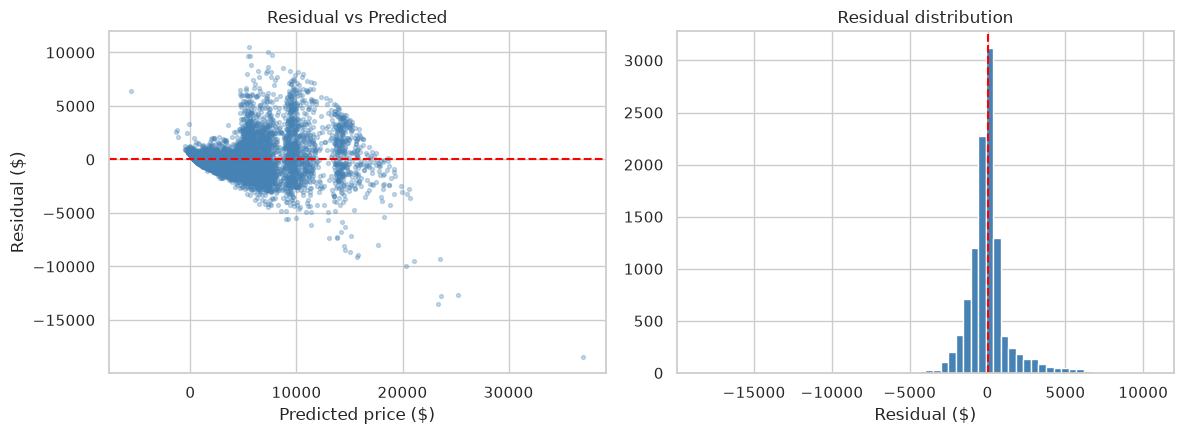

Mean residual: 13.0   Std: 1453.6
Predictions below $0: 84 of 10784


In [10]:
residuals = y_test - pred_test
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(pred_test, residuals, alpha=0.3, s=8, color="steelblue")
axes[0].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[0].set_xlabel("Predicted price ($)")
axes[0].set_ylabel("Residual ($)")
axes[0].set_title("Residual vs Predicted")

axes[1].hist(residuals, bins=60, color="steelblue", edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual ($)")
axes[1].set_title("Residual distribution")
plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():.1f}   Std: {residuals.std():.1f}")
print(f"Predictions below $0: {(pred_test < 0).sum()} of {len(pred_test)}")

**Interpretation:** The residuals are not random noise, so the linear model is missing structure:

- **Curved pattern:** binned by predicted price, the mean residual is positive for the lowest predictions (about +$327), negative in the middle (about -$407 around $3,000 to $5,000), and positive again for the highest (about +$344). This is a sign that the true relationship is non-linear, as we saw in the carat scatter plot (Stage 1.4).
- **Funnel shape (heteroscedasticity):** the residual standard deviation grows from about $320 for the cheapest predictions to about $2,800 for the most expensive.
- **Impossible predictions:** 84 of 10,784 test diamonds get a *negative* predicted price, which a straight line cannot avoid.
- The histogram is centred on zero but has heavy tails, particularly on the positive side (we under-predict some expensive diamonds).

This points to polynomial features (Stage 3) and a log-transformed target (Bonus 1).

### 2.4 Coefficients

In [11]:
coef = pd.Series(lin_pipe["model"].coef_, index=num_feats)
print("Intercept:", round(lin_pipe["model"].intercept_, 1))
coef.sort_values(key=abs, ascending=False).to_frame("coefficient (per 1 std)")

Intercept: 3936.2


,coefficient (per 1 std)
carat,5172.7694
x,-3509.2307
y,3480.8100
z,-1459.9574
table,-204.7871
depth,-94.2372


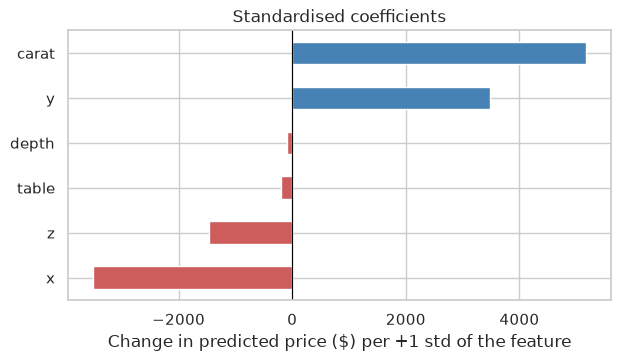

In [12]:
coef.sort_values().plot.barh(color=["indianred" if v < 0 else "steelblue" for v in coef.sort_values()], figsize=(7, 3.5))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Standardised coefficients")
plt.xlabel("Change in predicted price ($) per +1 std of the feature")
plt.show()

**Most influential feature:** `carat`, with a coefficient of about +5,173 dollars per standard deviation. Because the features were standardised, the coefficients are directly comparable.

**Counter-intuitive signs:** Yes. `x` (-3,509) and `z` (-1,460) have *negative* coefficients, i.e. the model says a bigger stone is cheaper, which makes no sense; `y` is +3,481 and cancels most of `x`. `depth` (-94) and `table` (-205) are small negative values and plausible (a poorly proportioned stone is worth slightly less).

**Explanation:** the signs of `x`, `y`, `z` are an artefact of **multicollinearity** (correlated at about 0.95 to 0.99 with `carat` and with each other). When features carry the same information, the model splits the effect between them in an unstable way, and individual coefficients lose their meaning even though the *predictions* remain fine. A 1-feature model would show a positive sign for each. Do not read those coefficients as "the effect of x on price".

---
## Stage 3: Polynomial Regression on `carat`

### 3.1 Train degrees 1, 2, 3, 5 with a `Pipeline`

In [13]:
Xc = df_clean[["carat"]]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, y, test_size=0.2, random_state=42)

degrees = [1, 2, 3, 5]
poly_models, rows = {}, []
for deg in degrees:
    pipe = Pipeline([
        ("poly", PolynomialFeatures(degree=deg, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ])
    pipe.fit(Xc_train, yc_train)
    poly_models[deg] = pipe
    p_te = pipe.predict(Xc_test)
    rows.append({
        "degree": deg,
        "R2 train": pipe.score(Xc_train, yc_train),
        "R2 test": r2_score(yc_test, p_te),
        "RMSE test": np.sqrt(mean_squared_error(yc_test, p_te)),
    })

### 3.2 Comparison table and fitted curves

In [14]:
cmp = pd.DataFrame(rows).set_index("degree")
cmp["gap (train - test)"] = cmp["R2 train"] - cmp["R2 test"]
cmp

,R2 train,R2 test,RMSE test,gap (train - test)
degree,,,,
1,0.8485,0.8524,1524.9755,-0.0039
2,0.8500,0.8550,1511.9567,-0.0050
3,0.8643,0.8682,1441.4514,-0.0039
5,0.8693,0.8726,1416.7896,-0.0033


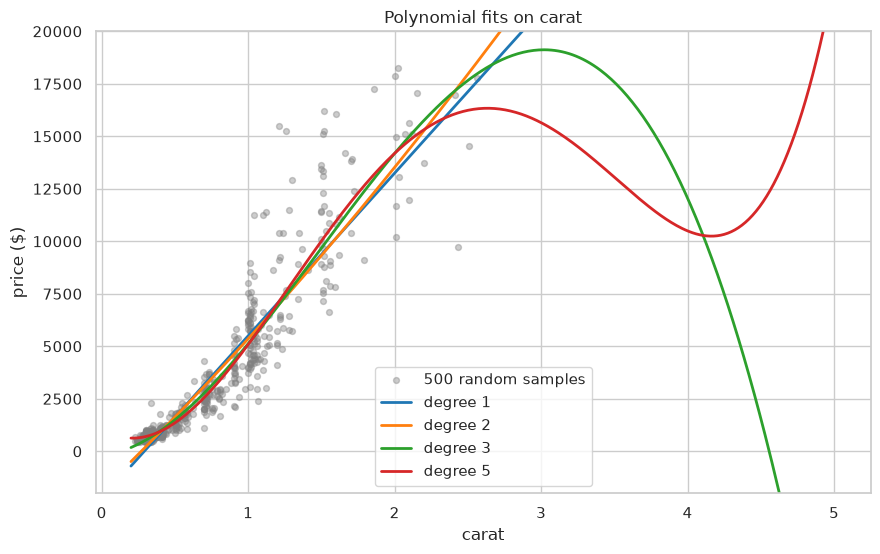

In [15]:
sample = df_clean.sample(500, random_state=42)
grid = pd.DataFrame({"carat": np.linspace(df_clean.carat.min(), df_clean.carat.max(), 400)})

plt.figure(figsize=(10, 6))
plt.scatter(sample.carat, sample.price, alpha=0.4, s=18, color="gray", label="500 random samples")
for deg, c in zip(degrees, ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    plt.plot(grid.carat, poly_models[deg].predict(grid), color=c, linewidth=2, label=f"degree {deg}")
plt.ylim(-2000, 20000)
plt.xlabel("carat")
plt.ylabel("price ($)")
plt.title("Polynomial fits on carat")
plt.legend()
plt.show()

### 3.3 Overfitting and the optimal degree

| degree | R² train | R² test | RMSE test |
|---|---|---|---|
| 1 | 0.8485 | 0.8524 | 1525.0 |
| 2 | 0.8500 | 0.8550 | 1512.0 |
| 3 | 0.8643 | 0.8682 | 1441.5 |
| 5 | 0.8693 | 0.8726 | 1416.8 |

**Which degree overfits? None of them, on this data.** Overfitting would show as R² train clearly above R² test. Here the test R² is actually slightly *higher* than the train R² for every degree (gap about -0.003 to -0.004; this is only due to which rows landed in the random test set). With about 43,000 training rows and at most 5 parameters, the models are far too simple to memorise noise. The curves do misbehave where data is sparse, though: only 32 diamonds are above 3 carats. Degree 3 predicts about $19,100 at 3 carats but falls to about -$14,900 at 5 carats, and degree 5 wobbles (about $15,600 at 3 carats, $10,500 at 4, $22,500 at 5). This is the first sign of overfitting-style instability, and it would get worse if we kept raising the degree.

**Which degree is optimal?** Degree 1 and 2 **underfit**: R² only 0.85, and degree 2 improves RMSE by just $13 over the straight line. Degree 3 gives the big jump (RMSE 1,512 to 1,441, -$71). Degree 5 adds only another $25 (1.7%) of improvement on top of degree 3.

**My choice: degree 5 by test RMSE (1,416.8), with degree 3 as the simpler runner-up.** Test performance, not train, decides, and degree 5 is lowest on it, so I carry it into Stage 4.1. Degree 3 gets most of the gain (-$71 of the total -$108 vs the straight line) with fewer terms. Neither should be trusted above roughly 3 carats, where there is too little data; a real deployment should flag such stones for manual appraisal.

---
## Stage 4: Interpretation and Reflection

### 4.1 Multiple linear regression vs polynomial on carat

In [16]:
mlr_rmse = res_lin["test"][1]
best_deg = cmp["RMSE test"].idxmin()
poly_rmse = cmp.loc[best_deg, "RMSE test"]
final = pd.DataFrame({
    "features": ["carat, depth, table, x, y, z", f"carat only (degree {best_deg})"],
    "RMSE test": [mlr_rmse, poly_rmse],
}, index=["Multiple linear regression", "Polynomial regression"])
final["R2 test"] = [res_lin["test"][2], cmp.loc[best_deg, "R2 test"]]
print(f"Improvement of polynomial over MLR: {(mlr_rmse - poly_rmse) / mlr_rmse:.1%}")
final

Improvement of polynomial over MLR: 2.5%


,features,RMSE test,R2 test
Multiple linear regression,"carat, depth, table, x, y, z",1453.6391,0.8659
Polynomial regression,carat only (degree 5),1416.7896,0.8726


**Which is better by RMSE test?** The polynomial model on `carat` alone (degree 5, RMSE 1,416.8) beats the multiple linear regression with six features (RMSE 1,453.6) by about $37 (2.5%).

**Why:** A single feature with a *curved* fit beats six features with a *straight* fit. The main limitation of the linear model is its shape, not the number of inputs. The five extra features add almost nothing because `x`, `y`, `z` are copies of the size information already in `carat` (multicollinearity), and `depth` and `table` are weakly related to price. The best of both would be a model with curvature **and** more informative features, which is what Bonus 1 and 2 test.

### 4.2 Three insights for a diamond company CEO

1. **Weight is what drives price, and it is not a straight line.** Carat alone explains about 87% of price differences. A 2-carat stone is worth far more than twice a 1-carat stone, so pricing "per carat" at a flat rate will under-price big diamonds and over-price small ones.
2. **Length, width and height add no new information beyond weight.** Measuring them gives almost nothing extra for predicting price. Depth and table percentages hardly matter on their own. Money spent collecting these numbers would be better spent on quality grades.
3. **Quality grades (cut, colour, clarity) are the missing piece.** Using only measurements, our price estimate is off by about $1,400 on average. Adding the three grades cuts that error by about 25% (Bonus 2). Our estimates are least reliable for the largest and most expensive stones, so those should still be appraised by an expert.

---
## Bonus 1: Log-transform the target

Original MAE=   873.51  RMSE=  1453.64  R2=0.8659
Log      MAE=   792.28  RMSE=  1443.93  R2=0.8677


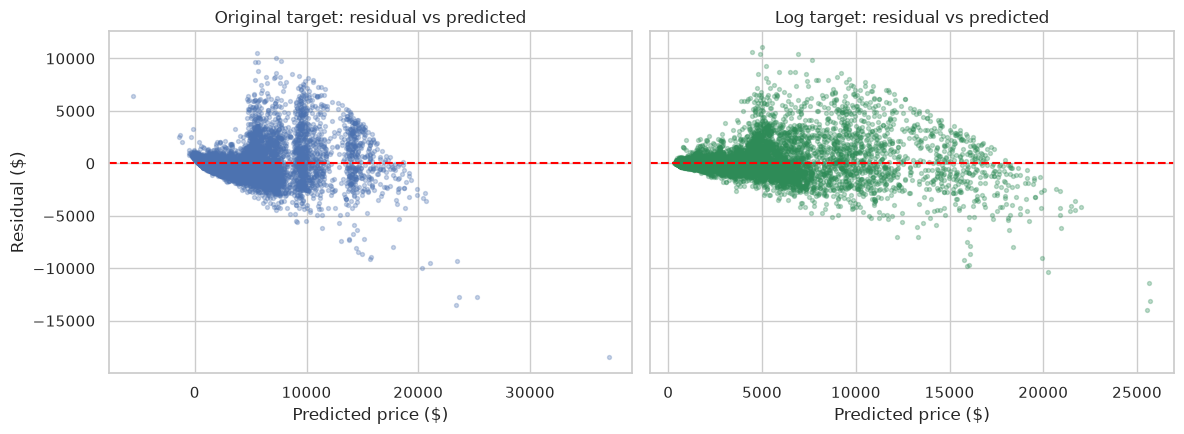

In [17]:
log_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])
log_pipe.fit(X_train, np.log(y_train))
pred_log = np.exp(log_pipe.predict(X_test))

b1_orig = report("Original", y_test, pred_test)
b1_log = report("Log", y_test, pred_log)

res_log = y_test - pred_log
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axes[0].scatter(pred_test, residuals, alpha=0.3, s=8)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Original target: residual vs predicted")
axes[1].scatter(pred_log, res_log, alpha=0.3, s=8, color="seagreen")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Log target: residual vs predicted")
for ax in axes: ax.set_xlabel("Predicted price ($)")
axes[0].set_ylabel("Residual ($)")
plt.tight_layout()
plt.show()

**Comparison:** RMSE goes from 1,453.6 to 1,443.9 (-$10, about -0.7%) and R² from 0.8659 to 0.8677. The RMSE gain is small, but MAE falls from 873.5 to 792.3 (-9.3%), so the typical error improves more than the worst-case error. Predictions can also never go negative (`exp()` always returns a positive number).

**Why the gain in RMSE is small:** RMSE is dominated by the largest errors, and the largest dollar errors occur on the expensive stones. In log-space the model treats a 10% error on a $500 stone the same as a 10% error on a $10,000 stone, which fits the *percentage* structure of diamond pricing better, but it does not particularly try to minimise the dollar error on expensive stones, which is what RMSE measures. Note also that `exp(mean of log y)` estimates the median, not the mean, so the back-transformed predictions are biased slightly low.

**When does a target log-transform help?**
- The target is positive and right-skewed with a long tail (prices, incomes, populations).
- The error is proportional to the size of the target (a multiplicative relationship: heteroscedastic residuals that fan out).
- The relationship is closer to linear in log-space (price grows by a percentage per unit of a feature).
- You care about relative (percentage) error rather than absolute dollars.

It does not help when the target is already roughly symmetric, when it contains zeros or negatives, or when the metric is absolute dollars dominated by the extremes.

---
## Bonus 2: Encoding categorical features

In [18]:
cat_feats = ["cut", "color", "clarity"]
X_all = df_clean[num_feats + cat_feats]
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_all, y, test_size=0.2, random_state=42)

pre = ColumnTransformer([
    ("num", StandardScaler(), num_feats),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats),
])
full_pipe = Pipeline([("pre", pre), ("model", LinearRegression())])
full_pipe.fit(Xa_train, ya_train)
pred_full = full_pipe.predict(Xa_test)

b2_before = report("Before", ya_test, pred_test)
b2_after = report("After", ya_test, pred_full)
print(f"RMSE improvement: {(b2_before[1] - b2_after[1]) / b2_before[1]:.1%}")

Before   MAE=   873.51  RMSE=  1453.64  R2=0.8659
After    MAE=   716.53  RMSE=  1090.26  R2=0.9246
RMSE improvement: 25.0%


**Result:** Test RMSE drops from 1,453.6 to 1,090.3, a **25.0% improvement**, and R² rises from 0.866 to 0.925. The same split (`random_state=42`) is used for both models, so the comparison is fair, and the one-hot encoder lives inside the pipeline, so it is fitted on training data only.

**Why it helps:** `clarity` and `color` have a large effect on price that carat cannot capture. At the same weight, a flawless stone costs much more than a heavily included one. Because the rows were also shown to be confounded in Stage 1.4 (Fair cut stones are larger), cut only shows its real effect once carat is controlled for. Note that the model is still linear, so the residual curvature remains. A natural next step would be to combine the categorical features with a log target or a polynomial on carat.

---
## Bonus 3: Cross-validation and learning curves
Cross-validation is run on the **training set only**, so the test set stays untouched. The models compared are the best of Stage 2 (multiple linear regression) and the best of Stage 3 (degree-5 polynomial on carat); the Bonus 2 model is added as a reference.

In [19]:
poly5 = poly_models[5]
cv_models = {
    "MLR (Stage 2)": (lin_pipe, X_train),
    "Poly deg 5 on carat (Stage 3)": (poly5, Xc_train),
    "MLR + categoricals (Bonus 2)": (full_pipe, Xa_train),
}
cv_rows = []
for name, (m, Xs) in cv_models.items():
    scores = cross_val_score(m, Xs, y_train, cv=5, scoring="r2")
    rm = -cross_val_score(m, Xs, y_train, cv=5, scoring="neg_root_mean_squared_error")
    cv_rows.append({"model": name, "R2 mean": scores.mean(), "R2 std": scores.std(),
                    "RMSE mean": rm.mean(), "RMSE std": rm.std()})
    print(name, np.round(scores, 4))
pd.DataFrame(cv_rows).set_index("model")

MLR (Stage 2) [0.8656 0.8449 0.8624 0.8631 0.8628]
Poly deg 5 on carat (Stage 3) [0.8726 0.8206 0.8689 0.8683 0.8693]
MLR + categoricals (Bonus 2) [0.9248 0.9087 0.9192 0.9218 0.9219]


,R2 mean,R2 std,RMSE mean,RMSE std
model,,,,
MLR (Stage 2),0.8598,0.0075,1494.2940,50.4590
Poly deg 5 on carat (Stage 3),0.8599,0.0197,1490.8871,109.9547
MLR + categoricals (Bonus 2),0.9193,0.0056,1133.5576,47.3988


**Mean and standard deviation:** All three models are stable across folds, with R² standard deviations well below 0.03. The deg-5 polynomial has the highest variability of the three (its RMSE std is the largest), which fits its higher flexibility and the influence of a few extreme high-carat points that land in different folds. The model with categoricals has the best mean R² (0.919) and the lowest standard deviation (0.0056). The CV means agree with the single test split, so the earlier numbers were not a lucky split.

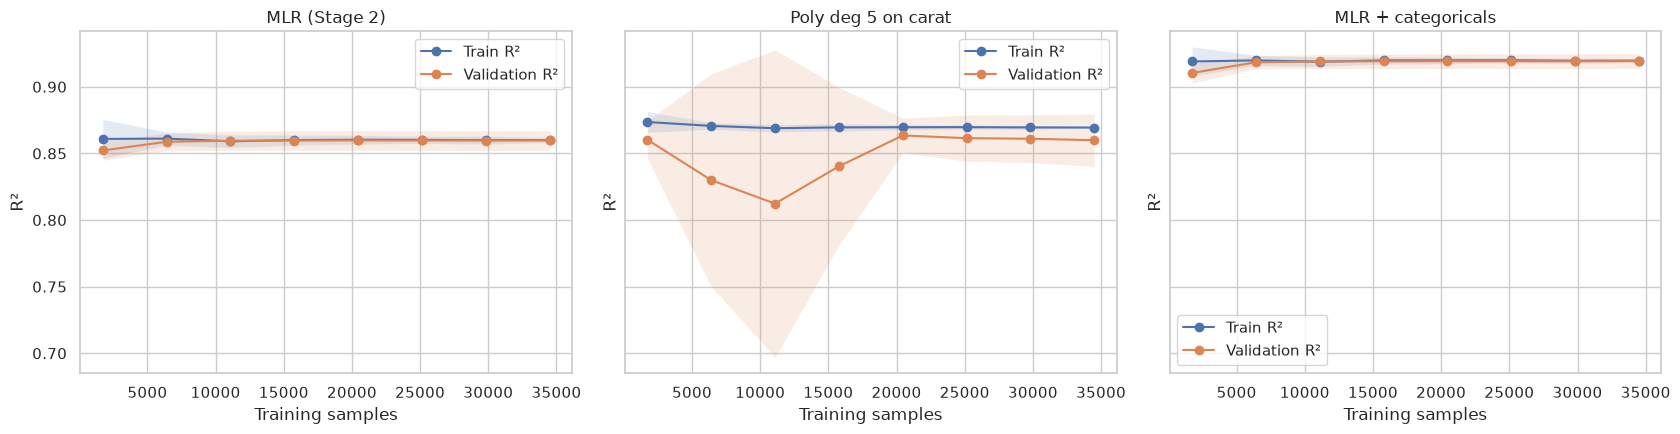

mlr   train R2 0.8600 | val R2 0.8598 | val R2 gain over last 3 sizes: +0.0001
poly  train R2 0.8694 | val R2 0.8599 | val R2 gain over last 3 sizes: -0.0015
full  train R2 0.9196 | val R2 0.9193 | val R2 gain over last 3 sizes: +0.0001


In [20]:
def plot_learning_curve(model, X_, y_, title, ax):
    sizes, tr, va = learning_curve(model, X_, y_, cv=5, scoring="r2",
                                   train_sizes=np.linspace(0.05, 1.0, 8), random_state=42, shuffle=True)
    ax.plot(sizes, tr.mean(axis=1), "o-", label="Train R²")
    ax.plot(sizes, va.mean(axis=1), "o-", label="Validation R²")
    ax.fill_between(sizes, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), alpha=0.15)
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.15)
    ax.set_title(title); ax.set_xlabel("Training samples"); ax.set_ylabel("R²"); ax.legend()
    return sizes, tr, va

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
lc = {}
lc["mlr"] = plot_learning_curve(lin_pipe, X_train, y_train, "MLR (Stage 2)", axes[0])
lc["poly"] = plot_learning_curve(poly5, Xc_train, y_train, "Poly deg 5 on carat", axes[1])
lc["full"] = plot_learning_curve(full_pipe, Xa_train, y_train, "MLR + categoricals", axes[2])
plt.tight_layout()
plt.show()

for k, (s, tr, va) in lc.items():
    print(f"{k:5s} train R2 {tr.mean(1)[-1]:.4f} | val R2 {va.mean(1)[-1]:.4f} | "
          f"val R2 gain over last 3 sizes: {va.mean(1)[-1] - va.mean(1)[-3]:+.4f}")

**Conclusion: more data would not help these models.** In all three plots the training and validation curves have already converged to nearly the same value, and the validation curve is flat for the last several points (the gain printed above is about 0.00). The gap between them is tiny, which means the models do not have a variance problem. The plateau is a **high-bias** limit: the model's form (a straight line or a low-order polynomial on a few features) caps the performance, not the amount of data.

To improve further, change the model rather than collect more rows: add the categorical features (already +0.06 R²), combine them with a log target and a polynomial on carat, add interaction terms, or move to non-linear models such as random forests or gradient boosting (covered later in the course).

---
## Summary

| Model | RMSE test | R² test |
|---|---|---|
| MLR, 6 numeric features | 1,453.6 | 0.866 |
| Polynomial deg 5, carat only | 1,416.8 | 0.873 |
| MLR, log target (Bonus 1) | 1,443.9 | 0.868 |
| MLR + cut/color/clarity (Bonus 2) | 1,090.3 | 0.925 |

The largest single gain came from adding the quality grades, not from changing the model complexity.